# AIML ZG519 – NLP Applications
## Assignment 2 – Programming Assignment: Information Extraction (10 Marks)

**File name:** `Assignment2_Programming_Group_86.ipynb`

Keep every section heading in this template. Each part needs code, executed outputs and a short markdown explanation.
Unexecuted or error-producing cells get no credit.

## Group details

| Field | Value |
| --- | --- |
| Group number | 86 |
| Problem statement (PS1–PS7) | PS4 – Scientific Knowledge Management: Compounds, Discoveries and Scientists |
| Dataset | CrossRE – Natural Science domain (`DFKI-SLT/cross_re`, config `science`) |

| # | Member name | BITS ID | Contribution |
| --- | --- | --- | --- |
| 1 | Prajwal Shetty K P | 2025AE05434 | Part A – data loading, span→BIO conversion, EDA; Part D – SciBERT fine-tuning (sub-token alignment); notebook integration |
| 2 | Neha Yadav | 2025AE05463 | Part B – CRF features, tuning and ablation; Part C – BiLSTM-CRF (GloVe + char-CNN) |
| 3 | Poornima Prakash Patil | 2025AE05411 | Part E – LLM zero-/few-shot NER (prompts, JSON parsing, CSV log); Part F – relation extraction |
| 4 | Narumalla Pavan Kumar | 2025AE05457 | Part G – model comparison, error analysis and reflection; Part 2 Situated Learning report |

## Problem statement and objective

An R&D organisation (a science-based manufacturer or publisher) keeps a large library of scientific articles, and researchers struggle to find which compounds, theories and scientists are discussed together. The knowledge-management team wants to extract scientific entities (chemical compounds, elements, proteins, enzymes, scientists, theories, awards, journals, astronomical objects, …) and the relations between them to power a searchable research index.

**Objective:** build and compare NER systems of increasing complexity on CrossRE-science (CRF → BiLSTM-CRF → fine-tuned SciBERT → prompted LLM), add a light relation-extraction step over gold entity pairs, and recommend, with evidence printed in this notebook, which approach the organisation should deploy.

## Approach overview

1. **Data preparation (A):** load the parquet revision, merge train+validation for training (as the brief requires), convert inclusive-end spans to BIO, verify the conversion by a round-trip check on every sentence plus 3 printed examples, and run the EDA. A fixed 10 % slice of train+validation (seed 42) is used only as a *development* set for model selection; every final model is retrained on all of train+validation.
2. **CRF (B):** `sklearn-crfsuite` with hand-crafted lexical, shape, affix, POS, context and domain (chemistry) features, with regularisation tuned on the dev slice and a feature-group ablation to justify the features.
3. **BiLSTM-CRF (C):** GloVe-100 word embeddings + character CNN + casing embedding → BiLSTM → CRF layer, with train/dev loss curves.
4. **Transformer (D):** fine-tune `allenai/scibert_scivocab_cased` for token classification with first-sub-token label alignment (other sub-tokens = -100).
5. **LLM (E):** local `Qwen2.5-7B-Instruct` (official 4-bit GGUF, run with llama.cpp; no paid API available), zero-shot and 5-shot JSON prompting on a fixed 100-sentence test sample; JSON is mapped back to token spans and scored with seqeval; prompts and raw responses are saved to CSV.
6. **Relation extraction (F):** all ordered gold-entity pairs, top-5 relations + OTHER + NO_RELATION (capped at 2× positives); logistic regression baseline vs. fine-tuned SciBERT with typed entity markers.
7. **Comparison (G):** a code-generated table on the shared sample, a categorised error analysis of the best model and a reflection on accuracy, cost, data size and domain.

**Metric everywhere:** entity-level, strict-match P/R/F1 from `seqeval` (`mode="strict"`, `scheme=IOB2`).

## 0. Setup

In [1]:
# Install what you need (Colab). Add packages as required.
%pip install -q datasets seqeval sklearn-crfsuite pytorch-crf gensim transformers accelerate nltk
%pip install -q llama-cpp-python --only-binary=:all: --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cpu
# !python -m spacy download en_core_web_sm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import random, json, re, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from collections import Counter, defaultdict
from IPython.display import display

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)

SEED = 42          # keep one seed for every random step and state it
def set_all_seeds(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_all_seeds()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    torch.set_num_threads(os.cpu_count())
OUT_DIR = "outputs"; os.makedirs(OUT_DIR, exist_ok=True)

# Run configuration (fixed for the submitted run)
CRF_MAX_ITER = 200
LSTM_EPOCHS = 40
BERT_EPOCHS = 12
RE_EPOCHS = 3
SAMPLE_SIZE_CFG = 100
LLM_MAX_NEW_TOKENS = 320
print(f"SEED={SEED} | device={DEVICE} | torch {torch.__version__} | threads={torch.get_num_threads()}")

SEED=42 | device=cpu | torch 2.14.0+cpu | threads=24


## Part A – Data preparation and EDA (1.0)

Load your PS dataset, convert span annotations to BIO tags, and report:
- sentence and token counts per split
- entity-type distribution
- average entity length in tokens
- 3 example sentences printed with their BIO tags

See the dataset notes in your PS brief (inclusive vs exclusive end indices, character offsets for PS2).

In [3]:
from datasets import load_dataset, concatenate_datasets

try:
    ds = load_dataset("DFKI-SLT/cross_re", "science", revision="refs/convert/parquet")
except Exception as e:
    # datasets>=4 no longer maps the parquet revision to named configs; read the very same
    # parquet files of the `science` config directly (identical content).
    print("Config-style loading not supported by this datasets version ->", type(e).__name__)
    base = "hf://datasets/DFKI-SLT/cross_re@refs%2Fconvert%2Fparquet/science/"
    ds = load_dataset("parquet", data_files={s: f"{base}{s}/0000.parquet" for s in ["train", "validation", "test"]})
print(ds)
train = concatenate_datasets([ds["train"], ds["validation"]])
test = ds["test"]
print(train[0]["sentence"], train[0]["ner"], train[0]["relations"])

Config-style loading not supported by this datasets version -> ValueError


DatasetDict({
    train: Dataset({
        features: ['doc_key', 'sentence', 'ner', 'relations'],
        num_rows: 103
    })
    validation: Dataset({
        features: ['doc_key', 'sentence', 'ner', 'relations'],
        num_rows: 351
    })
    test: Dataset({
        features: ['doc_key', 'sentence', 'ner', 'relations'],
        num_rows: 400
    })
})
['They', 'may', 'also', 'use', 'Adenosine', 'triphosphate', ',', 'Nitric', 'oxide', ',', 'and', 'ROS', 'for', 'signaling', 'in', 'the', 'same', 'ways', 'that', 'animals', 'do', '.'] [{'id-start': 4, 'id-end': 5, 'entity-type': 'chemicalcompound'}, {'id-start': 7, 'id-end': 8, 'entity-type': 'chemicalcompound'}, {'id-start': 11, 'id-end': 11, 'entity-type': 'chemicalcompound'}] []


In [4]:
def spans_to_bio(n_tokens, spans):
    """spans: list of (start, end_exclusive, type) in TOKEN indices.
    Returns a list of BIO tags. Convert inclusive ends (CrossRE) to exclusive before calling."""
    tags = ["O"] * n_tokens
    for start, end, etype in spans:
        tags[start] = f"B-{etype}"
        for i in range(start + 1, end):
            tags[i] = f"I-{etype}"
    return tags

def bio_to_spans(tags):
    """Inverse of spans_to_bio: BIO tags -> list of (start, end_exclusive, type)."""
    spans, start, etype = [], None, None
    for i, t in enumerate(list(tags) + ["O"]):
        continues = t.startswith("I-") and start is not None and t[2:] == etype
        if not continues:
            if start is not None:
                spans.append((start, i, etype))
            start, etype = (i, t[2:]) if t != "O" else (None, None)
    return spans

def fix_bio(tags):
    """Repair ill-formed IOB2 output: an I-X that does not continue an X entity becomes B-X."""
    out = list(tags)
    for i, t in enumerate(out):
        if t.startswith("I-") and (i == 0 or out[i - 1][2:] != t[2:]):
            out[i] = "B-" + t[2:]
    return out

# Sanity check
print(spans_to_bio(6, [(0, 2, "PER"), (4, 5, "LOC")]))
print(bio_to_spans(spans_to_bio(6, [(0, 2, "PER"), (4, 5, "LOC")])))

['B-PER', 'I-PER', 'O', 'O', 'B-LOC', 'O']
[(0, 2, 'PER'), (4, 5, 'LOC')]


In [5]:
CONV_STATS = Counter()

def convert_split(split, name):
    data = []
    for ex in split:
        toks = list(ex["sentence"])
        # CrossRE end indices are INCLUSIVE -> +1 to make them exclusive
        spans = sorted({(e["id-start"], e["id-end"] + 1, e["entity-type"]) for e in ex["ner"]})
        CONV_STATS[f"{name}: overlapping entity pairs"] += sum(
            1 for i, a in enumerate(spans) for b in spans[i + 1:] if a[0] < b[1] and b[0] < a[1])
        rels = {}
        for r in ex["relations"]:
            key = (r["id_1-start"], r["id_1-end"] + 1, r["id_2-start"], r["id_2-end"] + 1)
            if key in rels:                      # pair with a 2nd label -> keep the FIRST annotated label
                CONV_STATS[f"{name}: extra relation labels dropped"] += 1
                continue
            rels[key] = r["relation-type"]
        data.append({"doc_key": ex["doc_key"], "tokens": toks, "tags": spans_to_bio(len(toks), spans),
                     "spans": spans, "rels": rels, "split": name})
    return data

raw_splits = {s: convert_split(ds[s], s) for s in ["train", "validation", "test"]}
train_data = raw_splits["train"] + raw_splits["validation"]    # brief: train on train + validation
test_data = raw_splits["test"]

# Verification 1: round-trip BIO -> spans must reproduce the gold spans for EVERY sentence
for name, data in raw_splits.items():
    mismatches = sum(bio_to_spans(d["tags"]) != d["spans"] for d in data)
    print(f"{name:<11} sentences={len(data):>3}  BIO round-trip mismatches={mismatches}")
print(dict(CONV_STATS))

# Development slice (only for model selection / loss curves); final models use all of train_data
rng_split = random.Random(SEED)
perm = list(range(len(train_data))); rng_split.shuffle(perm)
n_dev = round(0.1 * len(train_data))
dev_data = [train_data[i] for i in sorted(perm[:n_dev])]
fit_data = [train_data[i] for i in sorted(perm[n_dev:])]
print(f"train+validation={len(train_data)} -> fit={len(fit_data)} / dev={len(dev_data)} (seed {SEED}); test={len(test_data)}")

train       sentences=103  BIO round-trip mismatches=0
validation  sentences=351  BIO round-trip mismatches=0
test        sentences=400  BIO round-trip mismatches=0
{'train: overlapping entity pairs': 0, 'train: extra relation labels dropped': 46, 'validation: overlapping entity pairs': 0, 'validation: extra relation labels dropped': 47, 'test: overlapping entity pairs': 0, 'test: extra relation labels dropped': 53}
train+validation=454 -> fit=409 / dev=45 (seed 42); test=400


In [6]:
# Verification 2: three tagged sentences, printed next to the original inclusive-end annotations
def show_tagged(d):
    print(f"[{d['doc_key']}]  {' '.join(d['tokens'])}")
    print("  dataset annotation (start, end_INCLUSIVE, type, text):",
          [(s, e - 1, t, " ".join(d["tokens"][s:e])) for s, e, t in d["spans"]])
    for tok, tag in zip(d["tokens"], d["tags"]):
        print(f"    {tok:<24}{tag}")
    print()

examples = [train_data[0]]
examples += [d for d in train_data
             if len(d["tokens"]) <= 30 and len({t for *_, t in d["spans"]}) >= 3
             and any(e - s >= 3 for s, e, _ in d["spans"])][:2]
for d in examples:
    show_tagged(d)

[science-train-1]  They may also use Adenosine triphosphate , Nitric oxide , and ROS for signaling in the same ways that animals do .
  dataset annotation (start, end_INCLUSIVE, type, text): [(4, 5, 'chemicalcompound', 'Adenosine triphosphate'), (7, 8, 'chemicalcompound', 'Nitric oxide'), (11, 11, 'chemicalcompound', 'ROS')]
    They                    O
    may                     O
    also                    O
    use                     O
    Adenosine               B-chemicalcompound
    triphosphate            I-chemicalcompound
    ,                       O
    Nitric                  B-chemicalcompound
    oxide                   I-chemicalcompound
    ,                       O
    and                     O
    ROS                     B-chemicalcompound
    for                     O
    signaling               O
    in                      O
    the                     O
    same                    O
    ways                    O
    that                    O
    animals       

,sentences,tokens,avg tokens/sent,max tokens/sent,entities,entities/sent,avg entity len (tokens),entity tokens %,relations
split,,,,,,,,,
train,103,3634,35.28,76,551,5.35,2.27,34.37,355
validation,351,12753,36.33,82,1994,5.68,2.22,34.77,1340
test,400,14304,35.76,84,2273,5.68,2.15,34.13,1393
train+validation,454,16387,36.09,82,2545,5.61,2.23,34.68,1695


,train+val,test,train+val %,test %,avg len (tokens)
astronomicalobject,359,271,14.1,11.9,1.28
misc,349,398,13.7,17.5,1.94
scientist,317,303,12.5,13.3,2.05
organisation,282,203,11.1,8.9,3.46
chemicalcompound,215,133,8.4,5.9,1.56
person,179,194,7.0,8.5,1.84
award,146,81,5.7,3.6,4.02
university,141,87,5.5,3.8,3.12
academicjournal,136,121,5.3,5.3,3.23
location,128,128,5.0,5.6,1.83


18 entity types: ['academicjournal', 'astronomicalobject', 'award', 'book', 'chemicalcompound', 'chemicalelement', 'country', 'discipline', 'enzyme', 'event', 'location', 'misc', 'organisation', 'person', 'protein', 'scientist', 'theory', 'university']
Rare types (<50 training mentions): ['book', 'chemicalelement', 'country', 'discipline', 'event', 'theory']
Majority type 'astronomicalobject' = 14.1% of training mentions; rarest 'book' = 6 mentions


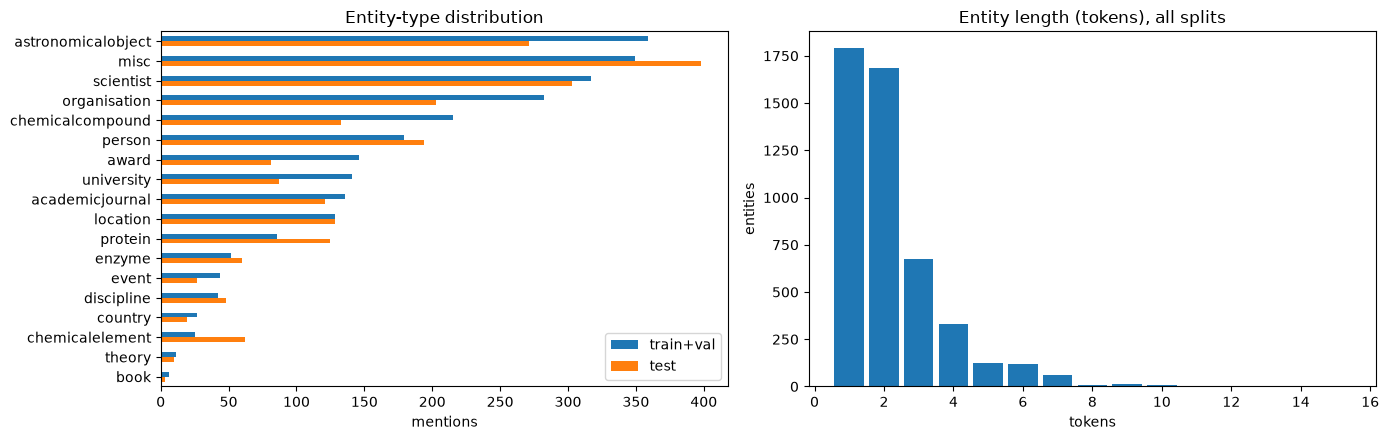

In [7]:
def split_stats(name, data):
    ents = [s for d in data for s in d["spans"]]
    n_tok = sum(len(d["tokens"]) for d in data)
    return {"split": name, "sentences": len(data), "tokens": n_tok,
            "avg tokens/sent": n_tok / len(data), "max tokens/sent": max(len(d["tokens"]) for d in data),
            "entities": len(ents), "entities/sent": len(ents) / len(data),
            "avg entity len (tokens)": np.mean([e - s for s, e, _ in ents]),
            "entity tokens %": 100 * sum(e - s for s, e, _ in ents) / n_tok,
            "relations": sum(len(d["rels"]) for d in data)}

eda = pd.DataFrame([split_stats(n, d) for n, d in
                    [("train", raw_splits["train"]), ("validation", raw_splits["validation"]),
                     ("test", test_data), ("train+validation", train_data)]]).set_index("split").round(2)
display(eda)

def type_counter(data): return Counter(t for d in data for *_, t in d["spans"])
all_spans = [(d, s) for d in train_data + test_data for s in d["spans"]]
type_df = pd.DataFrame({"train+val": type_counter(train_data), "test": type_counter(test_data)}).fillna(0).astype(int)
type_df["train+val %"] = (100 * type_df["train+val"] / type_df["train+val"].sum()).round(1)
type_df["test %"] = (100 * type_df["test"] / type_df["test"].sum()).round(1)
len_by_type = defaultdict(list)
for d, (s, e, t) in all_spans: len_by_type[t].append(e - s)
type_df["avg len (tokens)"] = pd.Series({t: np.mean(v) for t, v in len_by_type.items()}).round(2)
type_df = type_df.sort_values("train+val", ascending=False)
display(type_df)

ENTITY_TYPES = sorted(type_df.index)
TRAIN_TYPE_COUNTS = type_counter(train_data)
RARE_TYPES = [t for t in ENTITY_TYPES if TRAIN_TYPE_COUNTS[t] < 50]
print(f"{len(ENTITY_TYPES)} entity types: {ENTITY_TYPES}")
print(f"Rare types (<50 training mentions): {RARE_TYPES}")
print(f"Majority type '{type_df.index[0]}' = {type_df['train+val %'].iloc[0]}% of training mentions; "
      f"rarest '{type_df.index[-1]}' = {type_df['train+val'].iloc[-1]} mentions")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
type_df[["train+val", "test"]].plot.barh(ax=ax[0]); ax[0].invert_yaxis()
ax[0].set_title("Entity-type distribution"); ax[0].set_xlabel("mentions")
lens = [e - s for _, (s, e, _) in all_spans]
ax[1].hist(lens, bins=range(1, max(lens) + 2), align="left", rwidth=0.85)
ax[1].set_title("Entity length (tokens), all splits"); ax[1].set_xlabel("tokens"); ax[1].set_ylabel("entities")
plt.tight_layout(); plt.show()

{{A_NOTES}}

## Part B – Classical NER: CRF (1.5)

Train a CRF with hand-crafted features (word shape, case, prefix/suffix, POS, neighbouring words). Justify the features.
Report entity-level P/R/F1 per type with seqeval.

In [8]:
import sklearn_crfsuite
import nltk
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from seqeval.scheme import IOB2

def seq_prf(y_true, y_pred):
    kw = dict(mode="strict", scheme=IOB2, zero_division=0)
    return {"P": precision_score(y_true, y_pred, **kw), "R": recall_score(y_true, y_pred, **kw),
            "F1": f1_score(y_true, y_pred, **kw)}

def seq_report(y_true, y_pred):
    print(classification_report(y_true, y_pred, mode="strict", scheme=IOB2, digits=4, zero_division=0))

nltk.download("averaged_perceptron_tagger_eng", quiet=True)
for d in train_data + test_data:                       # POS tags (NLTK averaged perceptron), computed once
    d["pos"] = [p for _, p in nltk.pos_tag(d["tokens"])]

def word_shape(w):
    return re.sub("[0-9]", "d", re.sub("[a-z]", "x", re.sub("[A-Z]", "X", w)))

def short_shape(w):
    return re.sub(r"(.)\1+", r"\1", word_shape(w))

CHEM_SUFFIXES = ("ase", "ide", "ate", "ite", "ine", "ium", "ene", "ane", "yl", "ol", "one", "in", "gen")
GREEK = re.compile("[α-ωΑ-Ω]")
FEATURE_GROUPS = ("lexical", "case_shape", "affix", "pos", "context", "domain")

def word2features(sent, i, pos=None, groups=FEATURE_GROUPS):
    w = sent[i]
    feats = {"bias": 1.0}
    if "lexical" in groups:
        feats.update({"word.lower": w.lower(), "len": min(len(w), 12)})
    if "case_shape" in groups:
        feats.update({"word.istitle": w.istitle(), "word.isupper": w.isupper(), "word.isdigit": w.isdigit(),
                      "has_digit": any(c.isdigit() for c in w), "has_hyphen": "-" in w,
                      "inner_upper": any(c.isupper() for c in w[1:]), "shape": word_shape(w)[:12],
                      "short_shape": short_shape(w)})
    if "affix" in groups:
        feats.update({f"suf{k}": w[-k:].lower() for k in (2, 3, 4)})
        feats.update({f"pre{k}": w[:k].lower() for k in (2, 3)})
    if "pos" in groups and pos is not None:
        feats.update({"pos": pos[i], "pos2": pos[i][:2]})
    if "domain" in groups:
        lw = w.lower()
        feats.update({"chem_suffix": next((s for s in CHEM_SUFFIXES if lw.endswith(s) and len(lw) > len(s) + 2), "none"),
                      "alnum_mix": bool(re.search(r"[A-Za-z]", w) and re.search(r"\d", w)),
                      "greek": bool(GREEK.search(w)), "ends_ase": lw.endswith("ase")})
    if "context" in groups:
        for off in (-2, -1, 1, 2):
            j = i + off
            if 0 <= j < len(sent):
                v = sent[j]
                feats.update({f"{off}:lower": v.lower(), f"{off}:istitle": v.istitle(),
                              f"{off}:isupper": v.isupper(), f"{off}:short_shape": short_shape(v)})
                if "pos" in groups and pos is not None:
                    feats[f"{off}:pos"] = pos[j]
            else:
                feats[f"{off}:pad"] = True
        if i > 0: feats["bigram-1"] = sent[i - 1].lower() + "|" + w.lower()
        if i < len(sent) - 1: feats["bigram+1"] = w.lower() + "|" + sent[i + 1].lower()
    return feats

def sent2features(d, groups=FEATURE_GROUPS):
    return [word2features(d["tokens"], i, d.get("pos"), groups) for i in range(len(d["tokens"]))]

def train_crf(data, c1, c2, groups=FEATURE_GROUPS):
    crf = sklearn_crfsuite.CRF(algorithm="lbfgs", c1=c1, c2=c2, max_iterations=CRF_MAX_ITER,
                               all_possible_transitions=True)
    crf.fit([sent2features(d, groups) for d in data], [d["tags"] for d in data])
    return crf

def crf_predict(crf, data, groups=FEATURE_GROUPS):
    return [fix_bio(p) for p in crf.predict([sent2features(d, groups) for d in data])]

print("Example feature dict for 'triphosphate':")
print(word2features(train_data[0]["tokens"], 5, train_data[0]["pos"]))

# The 45-sentence dev slice is too small for stable CRF decisions, so tuning and the feature
# ablation use 5-fold cross-validation on train+validation (folds run in parallel; test is never touched).
from joblib import Parallel, delayed
from sklearn.model_selection import KFold
FOLDS = list(KFold(5, shuffle=True, random_state=SEED).split(train_data))

def _fold_pred(tr_idx, va_idx, c1, c2, groups):
    m = train_crf([train_data[i] for i in tr_idx], c1, c2, groups)
    return crf_predict(m, [train_data[i] for i in va_idx], groups)

def cv_f1(c1, c2, groups=FEATURE_GROUPS):
    preds = Parallel(n_jobs=5)(delayed(_fold_pred)(tr, va, c1, c2, groups) for tr, va in FOLDS)
    y_true = [train_data[i]["tags"] for _, va in FOLDS for i in va]
    return seq_prf(y_true, [p for fold in preds for p in fold])

# 1) tune L1/L2 regularisation (5-fold CV)
grid = [(0.05, 0.01), (0.1, 0.05), (0.2, 0.01), (0.1, 0.1), (0.3, 0.05)]
tune_df = pd.DataFrame([{"c1": c1, "c2": c2, **cv_f1(c1, c2)} for c1, c2 in grid]).round(4)
display(tune_df)
best = tune_df.sort_values("F1", ascending=False).iloc[0]
CRF_C1, CRF_C2 = float(best.c1), float(best.c2)
print(f"Selected c1={CRF_C1}, c2={CRF_C2} (5-fold CV F1={best.F1:.4f})")

# 2) feature-group ablation (5-fold CV) – the justification of each feature group
abl_rows = [{"features": "all groups", "CV F1": best.F1}]
for g in FEATURE_GROUPS:
    abl_rows.append({"features": f"without {g}",
                     "CV F1": cv_f1(CRF_C1, CRF_C2, tuple(x for x in FEATURE_GROUPS if x != g))["F1"]})
abl_df = pd.DataFrame(abl_rows)
abl_df["delta vs all"] = abl_df["CV F1"] - abl_df["CV F1"].iloc[0]
display(abl_df.round(4))
# keep a group unless removing it improves CV F1 by more than 0.005
CRF_GROUPS = tuple(g for g in FEATURE_GROUPS
                   if abl_df.set_index("features").loc[f"without {g}", "delta vs all"] <= 0.005)
print("Feature groups used by the final CRF:", CRF_GROUPS)

# 3) final CRF on all of train+validation, predict the full test split
t0 = time.perf_counter()
crf = train_crf(train_data, CRF_C1, CRF_C2, CRF_GROUPS)
crf_train_time = time.perf_counter() - t0
t0 = time.perf_counter()
y_pred_crf = crf_predict(crf, test_data, CRF_GROUPS)
crf_infer_time = (time.perf_counter() - t0) / len(test_data)
y_test = [d["tags"] for d in test_data]
print(f"CRF trained in {crf_train_time:.1f}s; inference {1000 * crf_infer_time:.2f} ms/sentence")

Example feature dict for 'triphosphate':
{'bias': 1.0, 'word.lower': 'triphosphate', 'len': 12, 'word.istitle': False, 'word.isupper': False, 'word.isdigit': False, 'has_digit': False, 'has_hyphen': False, 'inner_upper': False, 'shape': 'xxxxxxxxxxxx', 'short_shape': 'x', 'suf2': 'te', 'suf3': 'ate', 'suf4': 'hate', 'pre2': 'tr', 'pre3': 'tri', 'pos': 'NN', 'pos2': 'NN', 'chem_suffix': 'ate', 'alnum_mix': False, 'greek': False, 'ends_ase': False, '-2:lower': 'use', '-2:istitle': False, '-2:isupper': False, '-2:short_shape': 'x', '-2:pos': 'VB', '-1:lower': 'adenosine', '-1:istitle': True, '-1:isupper': False, '-1:short_shape': 'Xx', '-1:pos': 'NNP', '1:lower': ',', '1:istitle': False, '1:isupper': False, '1:short_shape': ',', '1:pos': ',', '2:lower': 'nitric', '2:istitle': True, '2:isupper': False, '2:short_shape': 'Xx', '2:pos': 'NNP', 'bigram-1': 'adenosine|triphosphate', 'bigram+1': 'triphosphate|,'}


,c1,c2,P,R,F1
0,0.05,0.01,0.5954,0.5544,0.5742
1,0.10,0.05,0.5903,0.5485,0.5686
2,0.20,0.01,0.5797,0.5399,0.5591
3,0.10,0.10,0.5974,0.5532,0.5745
4,0.30,0.05,0.5875,0.5473,0.5667


Selected c1=0.1, c2=0.1 (5-fold CV F1=0.5745)


,features,CV F1,delta vs all
0,all groups,0.5745,0.0000
1,without lexical,0.5710,-0.0035
2,without case_shape,0.5659,-0.0086
3,without affix,0.5490,-0.0255
4,without pos,0.5739,-0.0006
5,without context,0.5639,-0.0106
6,without domain,0.5692,-0.0053


Feature groups used by the final CRF: ('lexical', 'case_shape', 'affix', 'pos', 'context', 'domain')


CRF trained in 13.0s; inference 1.22 ms/sentence


In [9]:
print("CRF – entity-level strict seqeval report on the FULL test split")
seq_report(y_test, y_pred_crf)
crf_scores = seq_prf(y_test, y_pred_crf)
print({k: round(v, 4) for k, v in crf_scores.items()})

state_feats = Counter(crf.state_features_).most_common(15)
print("\nTop-15 positive state features (feature, label) -> weight:")
for (attr, label), w in state_feats:
    print(f"  {w:7.3f}  {label:<22} {attr}")

CRF – entity-level strict seqeval report on the FULL test split
                    precision    recall  f1-score   support

   academicjournal     0.8427    0.6198    0.7143       121
astronomicalobject     0.8417    0.8635    0.8525       271
             award     0.7931    0.8519    0.8214        81
              book     0.0000    0.0000    0.0000         3
  chemicalcompound     0.4828    0.5263    0.5036       133
   chemicalelement     0.7941    0.4355    0.5625        62
           country     0.6667    0.2105    0.3200        19
        discipline     0.8182    0.3750    0.5143        48
            enzyme     0.7209    0.5167    0.6019        60
             event     0.6842    0.4815    0.5652        27
          location     0.4643    0.4062    0.4333       128
              misc     0.4103    0.2990    0.3459       398
      organisation     0.5397    0.6700    0.5978       203
            person     0.5036    0.3608    0.4204       194
           protein     0.4487    0.

{{B_NOTES}}

## Part C – Deep learning NER: BiLSTM / BiLSTM-CRF (1.5)

Use pretrained word embeddings (GloVe or similar). Plot training and validation loss. Report seqeval P/R/F1 per type.

In [10]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torchcrf import CRF
from gensim.models import KeyedVectors
from huggingface_hub import snapshot_download

# Pretrained GloVe (6B tokens, 100-d, lower-cased) – gensim KeyedVectors mirror on the HF hub
glove_dir = snapshot_download("fse/glove-wiki-gigaword-100")
glove = KeyedVectors.load(os.path.join(glove_dir, "glove-wiki-gigaword-100.model"))
EMB_DIM = glove.vector_size

TAGS = ["O"] + [f"{p}-{t}" for t in ENTITY_TYPES for p in ("B", "I")]
tag2id = {t: i for i, t in enumerate(TAGS)}; id2tag = {i: t for t, i in tag2id.items()}

# Word vocabulary: every training word + any other word that has a GloVe vector (no labels used)
train_words = {w.lower() for d in train_data for w in d["tokens"]}
other_words = {w.lower() for d in test_data for w in d["tokens"]} - train_words
itos = ["<pad>", "<unk>"] + sorted(train_words | {w for w in other_words if w in glove.key_to_index})
stoi = {w: i for i, w in enumerate(itos)}
rng_emb = np.random.RandomState(SEED)
emb_matrix = rng_emb.normal(0, 0.1, (len(itos), EMB_DIM)).astype(np.float32); emb_matrix[0] = 0
n_found = 0
for w, i in stoi.items():
    if w in glove.key_to_index:
        emb_matrix[i] = glove[w]; n_found += 1
def coverage(data, ents_only=False):
    toks = [d["tokens"][k].lower() for d in data for (s, e, _) in d["spans"] for k in range(s, e)] if ents_only \
        else [w.lower() for d in data for w in d["tokens"]]
    return 100 * np.mean([w in glove.key_to_index for w in toks])
print(f"vocab={len(itos)}  with GloVe vector={n_found}")
print(f"GloVe coverage – test tokens: {coverage(test_data):.1f}%  | test ENTITY tokens: {coverage(test_data, True):.1f}%")

chars = sorted({c for d in train_data for w in d["tokens"] for c in w})
ctoi = {c: i + 2 for i, c in enumerate(chars)}           # 0 pad, 1 unk
def case_id(w):
    if w.isdigit(): return 1
    if w.isupper(): return 2
    if w.istitle(): return 3
    if w.islower(): return 4
    if any(c.isdigit() for c in w): return 5
    if any(c.isupper() for c in w): return 6
    return 7

def encode(d):
    return {"words": [stoi.get(w.lower(), 1) for w in d["tokens"]],
            "chars": [[ctoi.get(c, 1) for c in w[:25]] for w in d["tokens"]],
            "cases": [case_id(w) for w in d["tokens"]],
            "tags": [tag2id[t] for t in d["tags"]]}

def collate(items):
    B, T = len(items), max(len(x["words"]) for x in items)
    L = max(len(c) for x in items for c in x["chars"])
    words = torch.zeros(B, T, dtype=torch.long); cases = torch.zeros(B, T, dtype=torch.long)
    tags = torch.zeros(B, T, dtype=torch.long); mask = torch.zeros(B, T, dtype=torch.bool)
    chars_t = torch.zeros(B, T, L, dtype=torch.long)
    for b, x in enumerate(items):
        n = len(x["words"])
        words[b, :n] = torch.tensor(x["words"]); cases[b, :n] = torch.tensor(x["cases"])
        tags[b, :n] = torch.tensor(x["tags"]); mask[b, :n] = True
        for t, c in enumerate(x["chars"]): chars_t[b, t, :len(c)] = torch.tensor(c)
    return words, chars_t, cases, tags, mask

class BiLSTMCRF(nn.Module):
    def __init__(self, emb_matrix, n_chars, n_tags, char_dim=30, char_filters=50, case_dim=8, hidden=128, dropout=0.5):
        super().__init__()
        self.word_emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        self.char_emb = nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.char_cnn = nn.Conv1d(char_dim, char_filters, kernel_size=3, padding=1)
        self.case_emb = nn.Embedding(8, case_dim)
        self.dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_matrix.shape[1] + char_filters + case_dim, hidden, batch_first=True, bidirectional=True)
        self.proj = nn.Linear(2 * hidden, n_tags)
        self.crf = CRF(n_tags, batch_first=True)

    def emissions(self, words, chars, cases, mask):
        B, T, L = chars.shape
        c = self.char_emb(chars.view(B * T, L)).transpose(1, 2)
        c = torch.relu(self.char_cnn(c)).max(dim=2).values.view(B, T, -1)
        x = self.dropout(torch.cat([self.word_emb(words), c, self.case_emb(cases)], dim=-1))
        lengths = mask.sum(1).cpu()
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        h, _ = pad_packed_sequence(self.lstm(packed)[0], batch_first=True, total_length=T)
        return self.proj(self.dropout(h))

    def loss(self, words, chars, cases, tags, mask):          # mean negative log-likelihood per sentence
        return -self.crf(self.emissions(words, chars, cases, mask), tags, mask=mask, reduction="mean")

    def decode(self, words, chars, cases, mask):
        return self.crf.decode(self.emissions(words, chars, cases, mask), mask=mask)

def lstm_predict(model, data, bs=64):
    model.eval(); preds = []
    with torch.no_grad():
        for i in range(0, len(data), bs):
            w, c, cs, _, m = collate([encode(d) for d in data[i:i + bs]])
            preds += [fix_bio([id2tag[t] for t in seq]) for seq in model.decode(w, c, cs, m)]
    return preds

def lstm_eval_loss(model, data, bs=64):
    model.eval(); tot = 0.0
    with torch.no_grad():
        for i in range(0, len(data), bs):
            batch = data[i:i + bs]
            tot += model.loss(*collate([encode(d) for d in batch])).item() * len(batch)
    return tot / len(data)

def train_bilstm(train_set, epochs, dev_set=None, bs=16, lr=1e-3):
    set_all_seeds()
    model = BiLSTMCRF(emb_matrix, len(chars) + 2, len(TAGS))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    enc_train = [encode(d) for d in train_set]
    hist = []
    for ep in range(1, epochs + 1):
        model.train(); order = list(range(len(enc_train))); random.shuffle(order); tot = 0.0
        for i in range(0, len(order), bs):
            batch = [enc_train[j] for j in order[i:i + bs]]
            loss = model.loss(*collate(batch))
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
            tot += loss.item() * len(batch)
        row = {"epoch": ep, "train_loss": tot / len(enc_train)}
        if dev_set is not None:
            row["dev_loss"] = lstm_eval_loss(model, dev_set)
            row["dev_F1"] = seq_prf([d["tags"] for d in dev_set], lstm_predict(model, dev_set))["F1"]
        hist.append(row)
    return model, pd.DataFrame(hist)

# Run 1: fit slice -> dev slice, to draw the loss curves and pick the number of epochs
t0 = time.perf_counter()
_, lstm_hist = train_bilstm(fit_data, LSTM_EPOCHS, dev_set=dev_data)
LSTM_BEST_EPOCH = int(lstm_hist.loc[lstm_hist.dev_F1.idxmax(), "epoch"])
print(f"dev run took {time.perf_counter() - t0:.0f}s; best dev F1={lstm_hist.dev_F1.max():.4f} at epoch {LSTM_BEST_EPOCH}")
display(lstm_hist[(lstm_hist.epoch % 5 == 0) | (lstm_hist.epoch == 1) | (lstm_hist.epoch == LSTM_BEST_EPOCH)].round(4))

# Run 2: final model on all of train+validation for the selected number of epochs
t0 = time.perf_counter()
lstm_model, _ = train_bilstm(train_data, LSTM_BEST_EPOCH)
lstm_train_time = time.perf_counter() - t0
t0 = time.perf_counter()
y_pred_lstm = lstm_predict(lstm_model, test_data)
lstm_infer_time = (time.perf_counter() - t0) / len(test_data)
print(f"final BiLSTM-CRF trained in {lstm_train_time:.0f}s; {sum(p.numel() for p in lstm_model.parameters()):,} parameters")

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1279.43it/s]

vocab=6584  with GloVe vector=6202
GloVe coverage – test tokens: 97.1%  | test ENTITY tokens: 93.2%


dev run took 155s; best dev F1=0.6022 at epoch 30


,epoch,train_loss,dev_loss,dev_F1
0,1,77.5195,52.8009,0.0000
4,5,28.4278,23.1290,0.4000
9,10,16.3768,16.4693,0.4762
14,15,10.9956,15.3952,0.4936
19,20,7.6329,14.6722,0.5470
24,25,5.4938,14.5848,0.5574
29,30,3.9816,13.6691,0.6022
34,35,3.1565,14.7902,0.5757
39,40,2.4418,13.7157,0.5577


final BiLSTM-CRF trained in 123s; 972,148 parameters


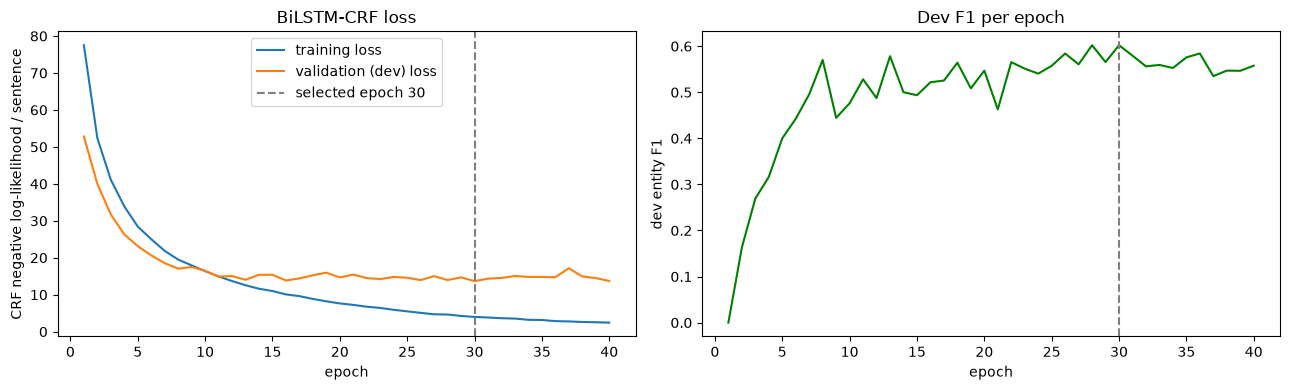

BiLSTM-CRF – entity-level strict seqeval report on the FULL test split
                    precision    recall  f1-score   support

   academicjournal     0.6928    0.8760    0.7737       121
astronomicalobject     0.8611    0.9151    0.8873       271
             award     0.7556    0.8395    0.7953        81
              book     0.0000    0.0000    0.0000         3
  chemicalcompound     0.4326    0.6992    0.5345       133
   chemicalelement     0.3333    0.0323    0.0588        62
           country     0.7500    0.3158    0.4444        19
        discipline     0.7500    0.4375    0.5526        48
            enzyme     0.6786    0.3167    0.4318        60
             event     0.5217    0.4444    0.4800        27
          location     0.7850    0.6562    0.7149       128
              misc     0.3925    0.3668    0.3792       398
      organisation     0.6535    0.7340    0.6914       203
            person     0.7688    0.6856    0.7248       194
           protein     0.400

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(lstm_hist.epoch, lstm_hist.train_loss, label="training loss")
ax[0].plot(lstm_hist.epoch, lstm_hist.dev_loss, label="validation (dev) loss")
ax[0].axvline(LSTM_BEST_EPOCH, ls="--", c="grey", label=f"selected epoch {LSTM_BEST_EPOCH}")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("CRF negative log-likelihood / sentence"); ax[0].legend(); ax[0].set_title("BiLSTM-CRF loss")
ax[1].plot(lstm_hist.epoch, lstm_hist.dev_F1, c="green"); ax[1].axvline(LSTM_BEST_EPOCH, ls="--", c="grey")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("dev entity F1"); ax[1].set_title("Dev F1 per epoch")
plt.tight_layout(); plt.show()

print("BiLSTM-CRF – entity-level strict seqeval report on the FULL test split")
seq_report(y_test, y_pred_lstm)
lstm_scores = seq_prf(y_test, y_pred_lstm)
print({k: round(v, 4) for k, v in lstm_scores.items()}, "| CRF:", {k: round(v, 4) for k, v in crf_scores.items()})

{{C_NOTES}}

## Part D – Transformer fine-tuning (2.0)

Fine-tune a BERT-family model for token classification (suggested model in your PS brief).
**Subword-to-word label alignment is mandatory and must be explained.** A helper is given below; you may adapt it.

In [12]:
from transformers import AutoTokenizer

MODEL_NAME = "allenai/scibert_scivocab_cased"   # suggested model for PS4
# NOTE: the SciBERT-cased checkpoint ships without a tokenizer_config, so the default would LOWER-CASE
# the input; do_lower_case=False keeps the casing the model was pre-trained on.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, do_lower_case=False)
label2id = {t: i for i, t in enumerate(TAGS)}; id2label = {i: t for t, i in label2id.items()}

def tokenize_and_align(tokens, word_labels, label2id):
    """Label only the first sub-token of each word; other sub-tokens and special tokens get -100
    so the loss ignores them."""
    enc = tokenizer(tokens, is_split_into_words=True, truncation=True, max_length=512)
    labels, prev = [], None
    for wid in enc.word_ids():
        if wid is None:
            labels.append(-100)
        elif wid != prev:
            labels.append(label2id[word_labels[wid]])
        else:
            labels.append(-100)
        prev = wid
    enc["labels"] = labels
    return enc

# Show the alignment on one example sentence from the dataset
ex = train_data[0]
enc_ex = tokenize_and_align(ex["tokens"], ex["tags"], label2id)
align_df = pd.DataFrame({"sub-token": tokenizer.convert_ids_to_tokens(enc_ex["input_ids"]),
                         "word_id": enc_ex.word_ids(),
                         "label id": enc_ex["labels"],
                         "label": [id2label.get(l, "(ignored: -100)") for l in enc_ex["labels"]]})
display(align_df.T)
n_sub = [len(tokenizer(d["tokens"], is_split_into_words=True)["input_ids"]) for d in train_data + test_data]
print(f"max sub-tokens per sentence = {max(n_sub)} (< 512, so no sentence is truncated)")

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
sub-token,[CLS],They,may,also,use,Aden,##osine,trip,##ho,##sp,...,signaling,in,the,same,ways,that,animals,do,.,[SEP]
word_id,NaN,0.0,1.0,2.0,3.0,4.0,4.0,5.0,5.0,5.0,...,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0,21.0,NaN
label id,-100,0,0,0,0,9,-100,10,-100,-100,...,0,0,0,0,0,0,0,0,0,-100
label,(ignored: -100),O,O,O,O,B-chemicalcompound,(ignored: -100),I-chemicalcompound,(ignored: -100),(ignored: -100),...,O,O,O,O,O,O,O,O,O,(ignored: -100)


max sub-tokens per sentence = 141 (< 512, so no sentence is truncated)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 39402.86it/s]


[transformers] BertForTokenClassification LOAD REPORT from: allenai/scibert_scivocab_cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	c

{'loss': '2.274', 'grad_norm': '5.099', 'learning_rate': '4.032e-05', 'epoch': '1'}


{'eval_loss': '1.199', 'eval_P': '0.3016', 'eval_R': '0.08261', 'eval_F1': '0.1297', 'eval_runtime': '1.568', 'eval_samples_per_second': '28.7', 'eval_steps_per_second': '1.276', 'epoch': '1'}


{'loss': '0.7939', 'grad_norm': '4.045', 'learning_rate': '4.644e-05', 'epoch': '2'}


... (31 outputs left out)

{'loss': '0.06085', 'grad_norm': '0.592', 'learning_rate': '1.255e-05', 'epoch': '7'}


{'loss': '0.04709', 'grad_norm': '1.14', 'learning_rate': '6.383e-06', 'epoch': '8'}


{'loss': '0.04013', 'grad_norm': '0.886', 'learning_rate': '2.128e-07', 'epoch': '9'}
{'train_runtime': '708.2', 'train_samples_per_second': '5.77', 'train_steps_per_second': '0.369', 'train_loss': '0.4197', 'epoch': '9'}


final SciBERT trained in 709s; 109,376,293 parameters


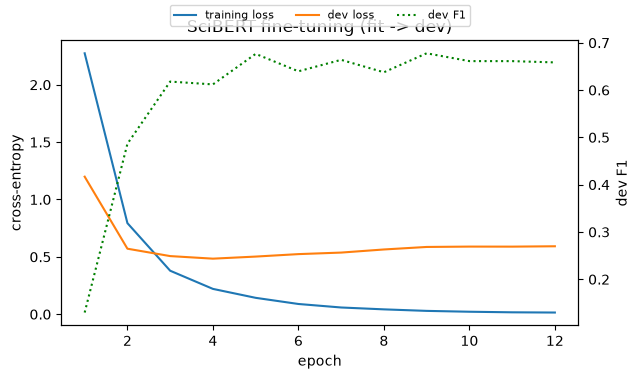

SciBERT – entity-level strict seqeval report on the FULL test split
                    precision    recall  f1-score   support

   academicjournal     0.8182    0.8926    0.8538       121
astronomicalobject     0.8750    0.9557    0.9136       271
             award     0.6415    0.8395    0.7273        81
              book     0.0000    0.0000    0.0000         3
  chemicalcompound     0.7299    0.7519    0.7407       133
   chemicalelement     0.8305    0.7903    0.8099        62
           country     0.5000    0.4211    0.4571        19
        discipline     0.5200    0.5417    0.5306        48
            enzyme     0.7400    0.6167    0.6727        60
             event     0.3793    0.4074    0.3929        27
          location     0.6797    0.6797    0.6797       128
              misc     0.3879    0.4347    0.4100       398
      organisation     0.7210    0.8276    0.7706       203
            person     0.7888    0.6546    0.7155       194
           protein     0.5422  

In [13]:
from transformers import (AutoModelForTokenClassification, TrainingArguments, Trainer,
                          DataCollatorForTokenClassification, set_seed as hf_set_seed)

def to_features(data):
    return [dict(tokenize_and_align(d["tokens"], d["tags"], label2id)) for d in data]

def word_level(pred_ids, label_ids):
    """Keep only positions whose label != -100, i.e. the first sub-token of each word -> word-level tags."""
    seqs = []
    for p_row, l_row in zip(pred_ids, label_ids):
        seqs.append(fix_bio([id2label[int(p)] for p, l in zip(p_row, l_row) if l != -100]))
    return seqs

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = word_level(logits.argmax(-1), labels)
    gold = [[id2label[int(l)] for l in row if l != -100] for row in labels]
    return seq_prf(gold, preds)

collator = DataCollatorForTokenClassification(tokenizer)

def train_bert(train_set, epochs, dev_set=None):
    hf_set_seed(SEED)
    model = AutoModelForTokenClassification.from_pretrained(MODEL_NAME, num_labels=len(TAGS),
                                                            id2label=id2label, label2id=label2id)
    steps = epochs * int(np.ceil(len(train_set) / 16))
    args = TrainingArguments(output_dir=os.path.join(OUT_DIR, "bert_ner"), per_device_train_batch_size=16,
                             per_device_eval_batch_size=32, learning_rate=5e-5, num_train_epochs=epochs,
                             weight_decay=0.01, warmup_steps=int(0.1 * steps), lr_scheduler_type="linear",
                             eval_strategy="epoch" if dev_set is not None else "no", save_strategy="no",
                             logging_strategy="epoch", report_to="none", seed=SEED, disable_tqdm=True)
    trainer = Trainer(model=model, args=args, train_dataset=to_features(train_set),
                      eval_dataset=to_features(dev_set) if dev_set is not None else None,
                      data_collator=collator, compute_metrics=compute_metrics)
    trainer.train()
    return trainer

def bert_predict(model, data, bs=32):
    model.eval(); preds = []
    for i in range(0, len(data), bs):
        batch = data[i:i + bs]
        enc = tokenizer([d["tokens"] for d in batch], is_split_into_words=True, truncation=True,
                        max_length=512, padding=True, return_tensors="pt")
        with torch.no_grad():
            pred = model(**{k: v.to(model.device) for k, v in enc.items()}).logits.argmax(-1).cpu().numpy()
        for b, d in enumerate(batch):
            tags, prev = ["O"] * len(d["tokens"]), None
            for pos, wid in enumerate(enc.word_ids(b)):
                if wid is not None and wid != prev:          # first sub-token of each word carries the word's label
                    tags[wid] = id2label[int(pred[b, pos])]
                prev = wid
            preds.append(fix_bio(tags))
    return preds

# Run 1: fit slice -> dev slice (epoch selection, curves)
t0 = time.perf_counter()
dev_trainer = train_bert(fit_data, BERT_EPOCHS, dev_set=dev_data)
logs = pd.DataFrame(dev_trainer.state.log_history)
bert_hist = logs.dropna(subset=["eval_F1"])[["epoch", "eval_loss", "eval_P", "eval_R", "eval_F1"]].merge(
    logs.dropna(subset=["loss"])[["epoch", "loss"]], on="epoch").rename(columns={"loss": "train_loss"})
BERT_BEST_EPOCH = int(round(bert_hist.loc[bert_hist.eval_F1.idxmax(), "epoch"]))
print(f"dev run took {time.perf_counter() - t0:.0f}s; best dev F1={bert_hist.eval_F1.max():.4f} at epoch {BERT_BEST_EPOCH}")
display(bert_hist.round(4))
del dev_trainer

# Run 2: final model on all of train+validation
t0 = time.perf_counter()
bert_trainer = train_bert(train_data, BERT_BEST_EPOCH)
bert_model = bert_trainer.model
bert_train_time = time.perf_counter() - t0
t0 = time.perf_counter()
y_pred_bert = bert_predict(bert_model, test_data)
bert_infer_time = (time.perf_counter() - t0) / len(test_data)
print(f"final SciBERT trained in {bert_train_time:.0f}s; {bert_model.num_parameters():,} parameters")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(bert_hist.epoch, bert_hist.train_loss, label="training loss")
ax.plot(bert_hist.epoch, bert_hist.eval_loss, label="dev loss")
ax2 = ax.twinx(); ax2.plot(bert_hist.epoch, bert_hist.eval_F1, c="green", ls=":", label="dev F1"); ax2.set_ylabel("dev F1")
ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy"); ax.set_title("SciBERT fine-tuning (fit -> dev)")
fig.legend(loc="upper center", ncol=3, fontsize=8); plt.tight_layout(); plt.show()

print("SciBERT – entity-level strict seqeval report on the FULL test split")
seq_report(y_test, y_pred_bert)
bert_scores = seq_prf(y_test, y_pred_bert)
print({k: round(v, 4) for k, v in bert_scores.items()})

{{D_NOTES}}

## Part E – LLM-based NER (1.5)

Run **zero-shot** and **few-shot (3–5 examples)** prompting on a fixed sample of at least 100 test sentences.
The LLM must return JSON. Map it back to token spans and score with seqeval.
Save prompts and raw responses to CSV, show the first 5, and count unparseable responses.

A simulated or hard-coded stand-in presented as an LLM scores zero. If you have no API access, use a small local open model and name it.

In [14]:
SAMPLE_SIZE = SAMPLE_SIZE_CFG
rng = random.Random(SEED)
sample_idx = sorted(rng.sample(range(len(test_data)), SAMPLE_SIZE))
sample_data = [test_data[i] for i in sample_idx]
y_sample = [d["tags"] for d in sample_data]
print(f"Fixed test sample: {SAMPLE_SIZE} sentences (random.Random({SEED}).sample), "
      f"{sum(len(d['spans']) for d in sample_data)} gold entities; first indices {sample_idx[:10]}")

# No paid API is available, so a REAL local open-weight instruction model is used:
# Qwen2.5-7B-Instruct, official 4-bit GGUF (Q4_K_M) from the Qwen HF repo, run with llama.cpp (llama-cpp-python)
# because it is ~5x faster than fp32 PyTorch on a CPU-only machine.
from llama_cpp import Llama
from huggingface_hub import hf_hub_download
LLM_NAME = "Qwen/Qwen2.5-7B-Instruct-GGUF (qwen2.5-7b-instruct-q4_k_m) via llama-cpp-python"   # model used
gguf_path = hf_hub_download("Qwen/Qwen2.5-7B-Instruct-GGUF", "qwen2.5-7b-instruct-q4_k_m-00001-of-00002.gguf")
hf_hub_download("Qwen/Qwen2.5-7B-Instruct-GGUF", "qwen2.5-7b-instruct-q4_k_m-00002-of-00002.gguf")
llm = Llama(model_path=gguf_path, n_ctx=4096, n_threads=max(1, os.cpu_count() // 2), seed=SEED, verbose=False)
print(f"Loaded {LLM_NAME}: {llm.n_ctx()} ctx, temperature 0 (greedy) decoding")

Fixed test sample: 100 sentences (random.Random(42).sample), 551 gold entities; first indices [3, 12, 13, 15, 16, 22, 23, 28, 33, 35]


Loaded Qwen/Qwen2.5-7B-Instruct-GGUF (qwen2.5-7b-instruct-q4_k_m) via llama-cpp-python: 4096 ctx, temperature 0 (greedy) decoding


In [15]:
def llm_json_to_bio(tokens, raw_response, entity_types):
    """Parse the LLM's JSON list of {"text":..., "type":...} and map each entity to the first
    matching token span not already tagged. Returns (bio_tags, parsed_ok, n_items, n_unmatched).
    Matching ignores case and whitespace, so 'NF-κB' or 'Ph.D.' match however the model spaces them."""
    tags = ["O"] * len(tokens)
    try:
        match = re.search(r"\[.*\]", raw_response, re.S)
        if match is None:
            return tags, False, 0, 0
        items = json.loads(match.group(0))
        if not isinstance(items, list):
            return tags, False, 0, 0
    except Exception:
        return tags, False, 0, 0
    lowered = [t.lower() for t in tokens]
    n_unmatched = 0
    for item in items:
        if not isinstance(item, dict):
            n_unmatched += 1; continue
        etype = re.sub(r"[\s_\-]", "", str(item.get("type", "")).strip().lower()).replace("organization", "organisation")
        target = re.sub(r"\s+", "", str(item.get("text", "")).lower())
        if etype not in entity_types or not target:
            n_unmatched += 1; continue
        found = False
        for s in range(len(tokens)):
            acc = ""
            for e in range(s, len(tokens)):
                acc += lowered[e]
                if acc == target:
                    if all(t == "O" for t in tags[s:e + 1]):
                        tags[s] = f"B-{etype}"
                        for k in range(s + 1, e + 1):
                            tags[k] = f"I-{etype}"
                        found = True
                    break
                if len(acc) >= len(target) or not target.startswith(acc):
                    break
            if found:
                break
        n_unmatched += (not found)
    return tags, True, len(items), n_unmatched

TYPE_DESC = {
    "scientist": "a person known as a scientist, researcher, astronomer, chemist, physicist, etc.",
    "person": "any other named person (not a scientist)",
    "organisation": "a named organisation, society, agency, company or institute (not a university)",
    "university": "a named university or college",
    "academicjournal": "a named scientific journal",
    "award": "a named prize, medal or award",
    "chemicalcompound": "a chemical compound or molecule (e.g. ATP, nitric oxide)",
    "chemicalelement": "a chemical element (e.g. helium, iron)",
    "protein": "a named protein, receptor or protein family",
    "enzyme": "a named enzyme (often ends in -ase)",
    "astronomicalobject": "a planet, moon, star, comet, asteroid, minor planet or galaxy",
    "discipline": "a field of science (e.g. physics, astronomy)",
    "theory": "a named scientific theory, law, effect, model or method",
    "location": "a city, region, observatory or other place (not a country)",
    "country": "a country",
    "event": "a named event, conference or competition",
    "book": "the title of a book",
    "misc": "other named scientific concepts or terms, nationalities and anything else that is named",
}
assert set(TYPE_DESC) == set(ENTITY_TYPES)

SYSTEM_PROMPT = "You are an information-extraction assistant for scientific text. You answer with JSON only."
INSTRUCTION = ("Extract every named entity from the sentence and give its type. Allowed types:\n"
               + "\n".join(f"- {t}: {desc}" for t, desc in TYPE_DESC.items())
               + "\nRules: copy each entity text exactly as written in the sentence; use only the types above; "
                 'answer ONLY with a JSON list such as [{"text": "...", "type": "..."}]; answer [] if there are none.')

def gold_json(d):
    return json.dumps([{"text": " ".join(d["tokens"][s:e]), "type": t} for s, e, t in d["spans"]], ensure_ascii=False)

# Few-shot examples: 5 training sentences chosen greedily to cover as many entity types as possible
cands = [d for d in train_data if 10 <= len(d["tokens"]) <= 32 and len(d["spans"]) >= 2]
FEW_SHOT, covered = [], set()
for _ in range(5):
    best_d = max(cands, key=lambda d: (len({t for *_, t in d["spans"]} - covered), -len(d["tokens"])))
    FEW_SHOT.append(best_d); covered |= {t for *_, t in best_d["spans"]}; cands.remove(best_d)
print(f"Few-shot examples cover {len(covered)}/{len(ENTITY_TYPES)} types: {sorted(covered)}")

def build_prompt(d, few_shot):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}]
    if few_shot:
        for k, ex in enumerate(FEW_SHOT):
            head = INSTRUCTION + "\n\n" if k == 0 else ""
            msgs += [{"role": "user", "content": f"{head}Sentence: {' '.join(ex['tokens'])}"},
                     {"role": "assistant", "content": gold_json(ex)}]
        msgs.append({"role": "user", "content": f"Sentence: {' '.join(d['tokens'])}"})
    else:
        msgs.append({"role": "user", "content": f"{INSTRUCTION}\n\nSentence: {' '.join(d['tokens'])}"})
    return msgs

def render(msgs):      # the exact chat (ChatML) text the model sees – saved to the CSV
    return "".join(f"<|im_start|>{m['role']}\n{m['content']}<|im_end|>\n" for m in msgs) + "<|im_start|>assistant\n"

def run_llm(prompts):
    outs, lat, toks = [], [], []
    for msgs in prompts:
        t0 = time.perf_counter()
        r = llm.create_chat_completion(messages=msgs, temperature=0.0, max_tokens=LLM_MAX_NEW_TOKENS, seed=SEED)
        lat.append(time.perf_counter() - t0)
        outs.append(r["choices"][0]["message"]["content"].strip())
        toks.append((r["usage"]["prompt_tokens"], r["usage"]["completion_tokens"]))
    return outs, lat, toks

records, llm_preds, llm_time = [], {}, {}
for setting, few in [("zero-shot", False), ("few-shot (5)", True)]:
    prompts = [build_prompt(d, few) for d in sample_data]
    t0 = time.perf_counter()
    responses, lat, toks = run_llm(prompts)
    llm_time[setting] = (time.perf_counter() - t0) / len(prompts)
    preds = []
    for i, d, msgs, r, l, (pt, ct) in zip(sample_idx, sample_data, prompts, responses, lat, toks):
        p = render(msgs)
        tags, ok, n_items, n_unm = llm_json_to_bio(d["tokens"], r, set(ENTITY_TYPES))
        preds.append(tags)
        records.append({"setting": setting, "test_index": i, "sentence": " ".join(d["tokens"]), "prompt": p,
                        "raw_response": r, "parsed_ok": ok, "n_entities_returned": n_items,
                        "n_unmatched_or_invalid": n_unm, "prompt_tokens": pt, "completion_tokens": ct,
                        "latency_s": round(l, 2)})
    llm_preds[setting] = preds
    print(f"{setting}: done, {llm_time[setting]:.2f} s/sentence on CPU")

llm_df = pd.DataFrame(records)
llm_df.to_csv("llm_ner_outputs.csv", index=False, encoding="utf-8")
print(f"Saved {len(llm_df)} prompts + raw responses to llm_ner_outputs.csv")
display(llm_df[["setting", "test_index", "sentence", "raw_response", "parsed_ok"]].head(5))
print("Prompt of the first record (zero-shot):\n" + llm_df.prompt.iloc[0])

summary_rows = []
for setting, preds in llm_preds.items():
    sub = llm_df[llm_df.setting == setting]
    summary_rows.append({"setting": setting, "unparseable responses": int((~sub.parsed_ok).sum()),
                         "entities returned": int(sub.n_entities_returned.sum()),
                         "unmatched / invalid-type items": int(sub.n_unmatched_or_invalid.sum()),
                         "avg prompt tokens": round(sub.prompt_tokens.mean()),
                         "s/sentence": round(llm_time[setting], 2), **seq_prf(y_sample, preds)})
llm_summary = pd.DataFrame(summary_rows).round(4); display(llm_summary)
for setting, preds in llm_preds.items():
    print(f"\n{LLM_NAME} {setting} – strict seqeval report on the {SAMPLE_SIZE}-sentence sample")
    seq_report(y_sample, preds)

Few-shot examples cover 16/18 types: ['astronomicalobject', 'award', 'chemicalcompound', 'chemicalelement', 'country', 'discipline', 'enzyme', 'event', 'location', 'misc', 'organisation', 'person', 'protein', 'scientist', 'theory', 'university']


zero-shot: done, 8.48 s/sentence on CPU


few-shot (5): done, 11.02 s/sentence on CPU
Saved 200 prompts + raw responses to llm_ner_outputs.csv


,setting,test_index,sentence,raw_response,parsed_ok
0,zero-shot,3,"Viral TK phosphorylates aciclovir into its monophosphate form , which is subsequently phosphorylated to active acicl...","[{""text"": ""TK"", ""type"": ""protein""}, {""text"": ""aciclovir"", ""type"": ""chemicalcompound""}, {""text"": ""aciclovir triphosha...",True
1,zero-shot,12,Polyethylene terephthalate ( PET ) bottles are made from ethylene and P-Xylene .,"[{""text"": ""Polyethylene terephthalate"", ""type"": ""chemicalcompound""}, {""text"": ""PET"", ""type"": ""chemicalcompound""}, {""...",True
2,zero-shot,13,Most widely used to assess potential synthetic lethal interactions is using siRNA and CRISPR to modify target genes .,[],True
3,zero-shot,15,"Cory 's work has been published in research journals including Blood ( journal ) , The EMBO Journal , Nature ( journ...","[{""text"": ""Blood"", ""type"": ""academicjournal""}, {""text"": ""The EMBO Journal"", ""type"": ""academicjournal""}, {""text"": ""Na...",True
4,zero-shot,16,"Albarn teamed up with Robert 3D Del Naja of Massive Attack and worked with Stop the War Coalition , CND and the Musl...","[{""text"": ""Albarn"", ""type"": ""person""}, {""text"": ""Robert 3D Del Naja"", ""type"": ""person""}, {""text"": ""Massive Attack"", ...",True


Prompt of the first record (zero-shot):
<|im_start|>system
You are an information-extraction assistant for scientific text. You answer with JSON only.<|im_end|>
<|im_start|>user
Extract every named entity from the sentence and give its type. Allowed types:
- scientist: a person known as a scientist, researcher, astronomer, chemist, physicist, etc.
- person: any other named person (not a scientist)
- organisation: a named organisation, society, agency, company or institute (not a university)
- university: a named university or college
- academicjournal: a named scientific journal
- award: a named prize, medal or award
- chemicalcompound: a chemical compound or molecule (e.g. ATP, nitric oxide)
- chemicalelement: a chemical element (e.g. helium, iron)
- protein: a named protein, receptor or protein family
- enzyme: a named enzyme (often ends in -ase)
- astronomicalobject: a planet, moon, star, comet, asteroid, minor planet or galaxy
- discipline: a field of science (e.g. physics, astrono

,setting,unparseable responses,entities returned,unmatched / invalid-type items,avg prompt tokens,s/sentence,P,R,F1
0,zero-shot,0,402,4,396,8.48,0.7613,0.5499,0.6386
1,few-shot (5),1,514,14,983,11.02,0.7280,0.6606,0.6927



Qwen/Qwen2.5-7B-Instruct-GGUF (qwen2.5-7b-instruct-q4_k_m) via llama-cpp-python zero-shot – strict seqeval report on the 100-sentence sample
                    precision    recall  f1-score   support

   academicjournal     0.9500    0.9048    0.9268        21
astronomicalobject     0.9057    0.6000    0.7218        80
             award     0.9524    0.9524    0.9524        21
              book     0.0000    0.0000    0.0000         0
  chemicalcompound     0.6071    0.5312    0.5667        32
   chemicalelement     0.0000    0.0000    0.0000         3
           country     0.8571    0.7500    0.8000         8
        discipline     1.0000    0.1429    0.2500        14
            enzyme     0.7143    0.3333    0.4545        15
             event     0.2500    0.2500    0.2500         4
          location     0.7917    0.6333    0.7037        30
              misc     0.5500    0.1089    0.1818       101
      organisation     0.8864    0.9070    0.8966        43
            perso

{{E_NOTES}}

## Part F – Relation extraction, light (1.5)

Candidates: all ordered pairs of gold entities in a sentence. Label = annotated relation, else `NO_RELATION`.
Cap `NO_RELATION` at twice the positive pairs in train and in test (use `SEED`).
CrossRE groups (PS3–PS7): keep the 5 most frequent relation types, map the rest to `OTHER`.

Method 1: classical baseline (e.g. logistic regression on entity types, words between, distance).
Method 2: LLM prompting **or** a fine-tuned transformer. Report macro-F1 and a confusion matrix for both.

Relation counts in train+validation (first label per pair): [('role', 350), ('physical', 251), ('origin', 175), ('part-of', 156), ('related-to', 144), ('named', 143), ('type-of', 132), ('general-affiliation', 60), ('win-defeat', 53), ('compare', 51), ('artifact', 37), ('usage', 31), ('cause-effect', 30), ('topic', 29), ('opposite', 21), ('social', 19), ('temporal', 13)]
Kept: ['role', 'physical', 'origin', 'part-of', 'related-to'] -> everything else = OTHER
  note: 1 self-relation(s) (same span as head and tail) excluded – not an entity pair


,role,physical,origin,part-of,related-to,OTHER,NO_RELATION
train,350,251,175,156,144,619,3390
test,234,224,94,90,126,624,2784


NO_RELATION candidates before cap: train=14821, test=13532 -> capped at 2x positives (seed 42)


LogReg: 6763 features; 5-fold CV on train picked C=10 (CV macro-F1=0.7411)

Method 1 – Logistic regression, TEST macro-F1 = 0.4590
              precision    recall  f1-score   support

        role     0.4611    0.3547    0.4010       234
    physical     0.7053    0.5982    0.6473       224
      origin     0.4674    0.4574    0.4624        94
     part-of     0.2000    0.1889    0.1943        90
  related-to     0.2619    0.1746    0.2095       126
       OTHER     0.5119    0.4135    0.4574       624
 NO_RELATION     0.8053    0.8797    0.8409      2784

    accuracy                         0.7198      4176
   macro avg     0.4876    0.4381    0.4590      4176
weighted avg     0.6998    0.7198    0.7070      4176



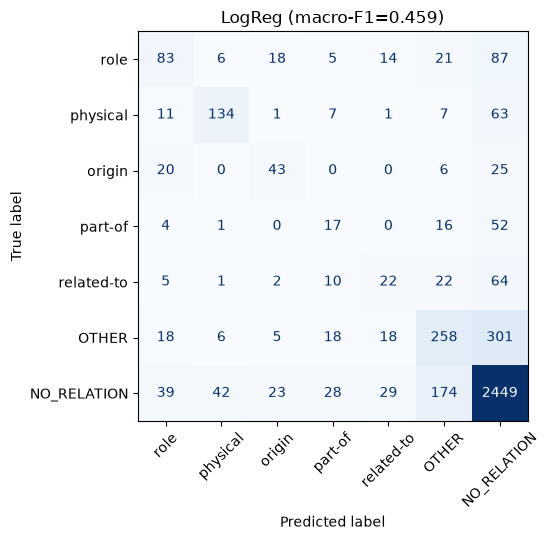

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report as cls_report, confusion_matrix, f1_score as sk_f1
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.feature_extraction import DictVectorizer
from sklearn.model_selection import GridSearchCV, StratifiedKFold

REL_COUNTS = Counter(r for d in train_data for r in d["rels"].values())
TOP5 = [r for r, _ in REL_COUNTS.most_common(5)]
RE_LABELS = TOP5 + ["OTHER", "NO_RELATION"]
print("Relation counts in train+validation (first label per pair):", REL_COUNTS.most_common())
print("Kept:", TOP5, "-> everything else = OTHER")

def build_pairs(data, seed=SEED):
    pos, neg = [], []
    for si, d in enumerate(data):
        for a in d["spans"]:
            for b in d["spans"]:
                if a == b: continue
                key = (a[0], a[1], b[0], b[1])
                if key in d["rels"]:
                    lab = d["rels"][key] if d["rels"][key] in TOP5 else "OTHER"
                    pos.append({"sent": si, "e1": a, "e2": b, "label": lab})
                else:
                    neg.append({"sent": si, "e1": a, "e2": b, "label": "NO_RELATION"})
    n_self = sum(1 for d in data for k in d["rels"] if k[:2] == k[2:])   # entity related to itself: not a pair
    assert len(pos) == sum(len(d["rels"]) for d in data) - n_self      # every other gold relation is a candidate
    if n_self: print(f"  note: {n_self} self-relation(s) (same span as head and tail) excluded – not an entity pair")
    neg_kept = random.Random(seed).sample(neg, min(len(neg), 2 * len(pos)))
    pairs = sorted(pos + neg_kept, key=lambda p: (p["sent"], p["e1"], p["e2"]))
    return pairs, len(neg)

re_train, n_neg_train = build_pairs(train_data)
re_test, n_neg_test = build_pairs(test_data)
re_counts = pd.DataFrame({"train": Counter(p["label"] for p in re_train),
                          "test": Counter(p["label"] for p in re_test)}).reindex(RE_LABELS).fillna(0).astype(int)
display(re_counts.T)
print(f"NO_RELATION candidates before cap: train={n_neg_train}, test={n_neg_test} -> capped at 2x positives (seed {SEED})")

def between(d, p):
    (s1, e1, _), (s2, e2, _) = p["e1"], p["e2"]
    return (e1, s2) if e1 <= s2 else (e2, s1)

def pair_features(p, data):
    d = data[p["sent"]]; toks = d["tokens"]
    (s1, e1, t1), (s2, e2, t2) = p["e1"], p["e2"]
    lo, hi = between(d, p)
    btw = [w.lower() for w in toks[lo:hi]]
    dist = hi - lo
    f = {f"t1={t1}": 1, f"t2={t2}": 1, f"pair={t1}|{t2}": 1, "e1_first": float(s1 < s2),
         "dist": min(dist, 30) / 30, f"dist_bin={min(dist // 3, 6)}": 1,
         "ents_between": sum(1 for s, e, _ in d["spans"] if s >= lo and e <= hi),
         f"head1={toks[e1 - 1].lower()}": 1, f"head2={toks[e2 - 1].lower()}": 1}
    for w in btw: f[f"btw={w}"] = 1
    if btw: f[f"btw_first={btw[0]}"] = 1; f[f"btw_last={btw[-1]}"] = 1
    if dist <= 4: f["btw_phrase=" + " ".join(btw)] = 1
    return f

vec = DictVectorizer()
X_tr = vec.fit_transform([pair_features(p, train_data) for p in re_train])
X_te = vec.transform([pair_features(p, test_data) for p in re_test])
y_tr = [p["label"] for p in re_train]; y_te = [p["label"] for p in re_test]

gs = GridSearchCV(LogisticRegression(max_iter=5000, class_weight="balanced"), {"C": [0.1, 0.3, 1, 3, 10]},
                  scoring="f1_macro", cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
gs.fit(X_tr, y_tr)
lr_re = gs.best_estimator_
print(f"LogReg: {X_tr.shape[1]} features; 5-fold CV on train picked C={gs.best_params_['C']} (CV macro-F1={gs.best_score_:.4f})")
y_pred_lr = lr_re.predict(X_te)
lr_macro = sk_f1(y_te, y_pred_lr, average="macro", labels=RE_LABELS)
print(f"\nMethod 1 – Logistic regression, TEST macro-F1 = {lr_macro:.4f}")
print(cls_report(y_te, y_pred_lr, labels=RE_LABELS, digits=4, zero_division=0))

def plot_cm(y_true, y_pred, title, ax):
    cm = confusion_matrix(y_true, y_pred, labels=RE_LABELS)
    ConfusionMatrixDisplay(cm, display_labels=RE_LABELS).plot(ax=ax, xticks_rotation=45, colorbar=False, cmap="Blues")
    ax.set_title(title)
    return cm

fig, ax = plt.subplots(figsize=(6.5, 5.5))
cm_lr = plot_cm(y_te, y_pred_lr, f"LogReg (macro-F1={lr_macro:.3f})", ax); plt.tight_layout(); plt.show()

Example input: @ * scientist * August Kopff @ , a colleague of # ^ scientist ^ Wolf # at Heidelberg , then discovered 617 Patroclus eight months after Achilles , and , in early 1907 , he discovered the largest of all Jupiter trojans , 624 Hektor . -> role


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 33169.07it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: allenai/scibert_scivocab_cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those 

{'loss': '1.547', 'grad_norm': '11.25', 'learning_rate': '2.225e-05', 'epoch': '1'}


{'loss': '0.7895', 'grad_norm': '30.8', 'learning_rate': '1.114e-05', 'epoch': '2'}


{'loss': '0.3897', 'grad_norm': '25.15', 'learning_rate': '3.492e-08', 'epoch': '3'}
{'train_runtime': '3981', 'train_samples_per_second': '3.832', 'train_steps_per_second': '0.24', 'train_loss': '0.9088', 'epoch': '3'}
SciBERT-RE trained 3 epochs on 5085 pairs in 3983s
 epoch     loss
   1.0 1.547257
   2.0 0.789460
   3.0 0.389660



Method 2 – fine-tuned SciBERT (entity markers), TEST macro-F1 = 0.5229
              precision    recall  f1-score   support

        role     0.5857    0.5256    0.5541       234
    physical     0.5789    0.7857    0.6667       224
      origin     0.5169    0.6489    0.5755        94
     part-of     0.2927    0.4000    0.3380        90
  related-to     0.2543    0.3492    0.2943       126
       OTHER     0.3608    0.5689    0.4415       624
 NO_RELATION     0.8807    0.7162    0.7900      2784

    accuracy                         0.6679      4176
   macro avg     0.4957    0.5707    0.5229      4176
weighted avg     0.7306    0.6679    0.6886      4176



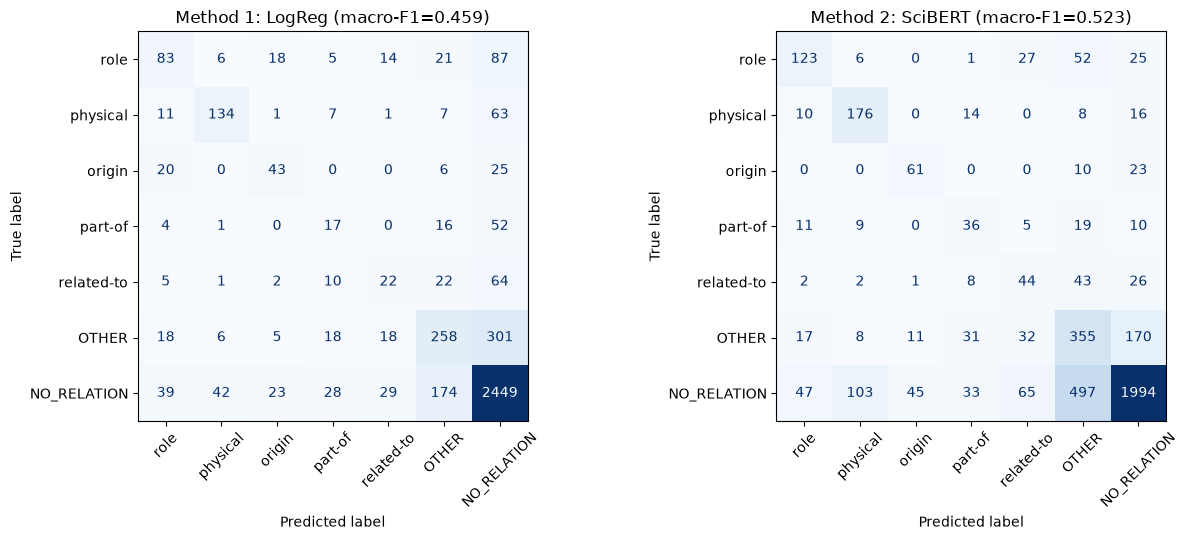

,LogReg F1,SciBERT F1,test support
role,0.4010,0.5541,234.0
physical,0.6473,0.6667,224.0
origin,0.4624,0.5755,94.0
part-of,0.1943,0.3380,90.0
related-to,0.2095,0.2943,126.0
OTHER,0.4574,0.4415,624.0
NO_RELATION,0.8409,0.7900,2784.0
macro-F1,0.4590,0.5229,4176.0


Macro-F1 over the 6 relation classes only (excluding NO_RELATION): LogReg=0.3953, SciBERT=0.4783


In [17]:
# Method 2 – fine-tuned SciBERT relation classifier with typed entity markers (Zhou & Chen, 2021):
#   subject -> "@ * type * ... @", object -> "# ^ type ^ ... #"; [CLS] representation -> 7-way softmax
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding

re_label2id = {l: i for i, l in enumerate(RE_LABELS)}

def marked_text(p, data):
    toks = data[p["sent"]]["tokens"]
    (s1, e1, t1), (s2, e2, t2) = p["e1"], p["e2"]
    out = []
    for i, w in enumerate(toks):
        if i == s1: out += ["@", "*", t1, "*"]
        if i == s2: out += ["#", "^", t2, "^"]
        out.append(w)
        if i == e1 - 1: out.append("@")
        if i == e2 - 1: out.append("#")
    return " ".join(out)

print("Example input:", marked_text(re_train[0], train_data), "->", re_train[0]["label"])

def re_features(pairs, data):
    feats = []
    for p in pairs:
        enc = tokenizer(marked_text(p, data), truncation=True, max_length=256)
        feats.append({**dict(enc), "labels": re_label2id[p["label"]]})
    return feats

counts = Counter(y_tr)
RE_CLASS_W = torch.tensor([len(y_tr) / (len(RE_LABELS) * counts[l]) for l in RE_LABELS], dtype=torch.float)

class WeightedTrainer(Trainer):        # same "balanced" class weighting as the logistic regression
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        out = model(**inputs)
        loss = nn.functional.cross_entropy(out.logits, labels, weight=RE_CLASS_W.to(out.logits.device))
        return (loss, out) if return_outputs else loss

hf_set_seed(SEED)
re_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(RE_LABELS),
    id2label=dict(enumerate(RE_LABELS)), label2id=re_label2id)
re_steps = RE_EPOCHS * int(np.ceil(len(re_train) / 16))
re_args = TrainingArguments(output_dir=os.path.join(OUT_DIR, "bert_re"), per_device_train_batch_size=16,
                            per_device_eval_batch_size=64, learning_rate=3e-5, num_train_epochs=RE_EPOCHS,
                            weight_decay=0.01, warmup_steps=int(0.1 * re_steps), save_strategy="no",
                            logging_strategy="epoch", report_to="none", seed=SEED, disable_tqdm=True)
re_trainer = WeightedTrainer(model=re_model, args=re_args, train_dataset=re_features(re_train, train_data),
                             data_collator=DataCollatorWithPadding(tokenizer))
t0 = time.perf_counter(); re_trainer.train(); re_train_time = time.perf_counter() - t0
print(f"SciBERT-RE trained {RE_EPOCHS} epochs on {len(re_train)} pairs in {re_train_time:.0f}s")
print(pd.DataFrame(re_trainer.state.log_history).dropna(subset=["loss"])[["epoch", "loss"]].to_string(index=False))

pred_ids = re_trainer.predict(re_features(re_test, test_data)).predictions.argmax(-1)
y_pred_bre = [RE_LABELS[i] for i in pred_ids]
bre_macro = sk_f1(y_te, y_pred_bre, average="macro", labels=RE_LABELS)
print(f"\nMethod 2 – fine-tuned SciBERT (entity markers), TEST macro-F1 = {bre_macro:.4f}")
print(cls_report(y_te, y_pred_bre, labels=RE_LABELS, digits=4, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
plot_cm(y_te, y_pred_lr, f"Method 1: LogReg (macro-F1={lr_macro:.3f})", ax[0])
cm_bre = plot_cm(y_te, y_pred_bre, f"Method 2: SciBERT (macro-F1={bre_macro:.3f})", ax[1])
plt.tight_layout(); plt.show()

re_cmp = pd.DataFrame({
    "LogReg F1": sk_f1(y_te, y_pred_lr, average=None, labels=RE_LABELS),
    "SciBERT F1": sk_f1(y_te, y_pred_bre, average=None, labels=RE_LABELS),
    "test support": [Counter(y_te)[l] for l in RE_LABELS]}, index=RE_LABELS)
re_cmp.loc["macro-F1"] = [lr_macro, bre_macro, len(y_te)]
display(re_cmp.round(4))
pos_labels = [l for l in RE_LABELS if l != "NO_RELATION"]
print(f"Macro-F1 over the 6 relation classes only (excluding NO_RELATION): "
      f"LogReg={sk_f1(y_te, y_pred_lr, average='macro', labels=pos_labels):.4f}, "
      f"SciBERT={sk_f1(y_te, y_pred_bre, average='macro', labels=pos_labels):.4f}")

{{F_NOTES}}

## Part G – Comparison, error analysis and reflection (1.0)

The table below must be built from variables computed above, on the **same** sample used in Part E.
Hand-typed numbers score zero for this part.

,Model,Precision,Recall,F1,F1 full test (400),train time (s),inference (ms/sentence),unparseable outputs
0,CRF,0.6469,0.5753,0.6090,0.5821,13.0035,1.2164,0
1,BiLSTM-CRF,0.6679,0.6570,0.6624,0.6507,122.5511,2.3924,0
2,Transformer (SciBERT),0.7126,0.7514,0.7314,0.7049,709.3722,40.3321,0
3,LLM zero-shot,0.7613,0.5499,0.6386,NaN,NaN,8483.9296,0
4,LLM few-shot,0.7280,0.6606,0.6927,NaN,NaN,11019.5782,1


Best model on the shared 100-sentence sample: Transformer (SciBERT) (F1=0.7314)
Gap best vs few-shot LLM: 0.0388 F1; few-shot vs zero-shot LLM: +0.0541 F1


,sample support,train mentions,CRF,BiLSTM-CRF,SciBERT,LLM 0-shot,LLM 5-shot
astronomicalobject,80,359,0.883,0.912,0.939,0.722,0.840
misc,101,349,0.369,0.389,0.465,0.182,0.104
scientist,103,317,0.744,0.853,0.930,0.820,0.887
organisation,43,282,0.626,0.701,0.763,0.897,0.867
chemicalcompound,32,215,0.523,0.543,0.678,0.567,0.704
person,34,179,0.317,0.703,0.781,0.483,0.722
award,21,146,0.756,0.760,0.706,0.952,0.884
university,13,141,0.800,0.720,0.833,0.783,0.727
academicjournal,21,136,0.811,0.625,0.884,0.927,0.950
location,30,128,0.471,0.679,0.655,0.704,0.767


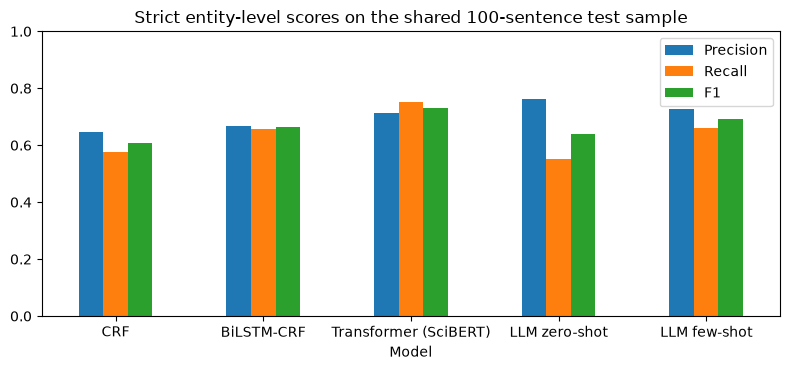

In [18]:
# fill y_true_sample and each model's predictions on the sample indices
y_true_sample = [test_data[i]["tags"] for i in sample_idx]
crf_sample = [y_pred_crf[i] for i in sample_idx]
lstm_sample = [y_pred_lstm[i] for i in sample_idx]
bert_sample = [y_pred_bert[i] for i in sample_idx]
llm0_sample = llm_preds["zero-shot"]
llmk_sample = llm_preds["few-shot (5)"]

full_test = {"CRF": crf_scores, "BiLSTM-CRF": lstm_scores, "Transformer (SciBERT)": bert_scores}
train_secs = {"CRF": crf_train_time, "BiLSTM-CRF": lstm_train_time, "Transformer (SciBERT)": bert_train_time}
infer_secs = {"CRF": crf_infer_time, "BiLSTM-CRF": lstm_infer_time, "Transformer (SciBERT)": bert_infer_time,
              "LLM zero-shot": llm_time["zero-shot"], "LLM few-shot": llm_time["few-shot (5)"]}
parse_fail = dict(zip(["LLM zero-shot", "LLM few-shot"], llm_summary["unparseable responses"]))

results = []
for name, preds in [("CRF", crf_sample), ("BiLSTM-CRF", lstm_sample), ("Transformer (SciBERT)", bert_sample),
                    ("LLM zero-shot", llm0_sample), ("LLM few-shot", llmk_sample)]:
    results.append({"Model": name,
                    "Precision": precision_score(y_true_sample, preds, mode="strict", scheme=IOB2, zero_division=0),
                    "Recall": recall_score(y_true_sample, preds, mode="strict", scheme=IOB2, zero_division=0),
                    "F1": f1_score(y_true_sample, preds, mode="strict", scheme=IOB2, zero_division=0),
                    "F1 full test (400)": full_test[name]["F1"] if name in full_test else np.nan,
                    "train time (s)": train_secs.get(name, np.nan),   # LLM: no training
                    "inference (ms/sentence)": 1000 * infer_secs[name],
                    "unparseable outputs": parse_fail.get(name, 0)})
comparison = pd.DataFrame(results)
display(comparison.round(4))

BEST_MODEL = comparison.loc[comparison.F1.idxmax(), "Model"]
best_preds_full = {"CRF": y_pred_crf, "BiLSTM-CRF": y_pred_lstm, "Transformer (SciBERT)": y_pred_bert}[BEST_MODEL] \
    if BEST_MODEL in full_test else None
r = comparison.set_index("Model")
print(f"Best model on the shared {SAMPLE_SIZE}-sentence sample: {BEST_MODEL} (F1={r.F1.max():.4f})")
print(f"Gap best vs few-shot LLM: {r.F1.max() - r.loc['LLM few-shot', 'F1']:.4f} F1; "
      f"few-shot vs zero-shot LLM: {r.loc['LLM few-shot', 'F1'] - r.loc['LLM zero-shot', 'F1']:+.4f} F1")

# Per-type F1 on the shared sample (where do the models differ?)
per_type = {}
for name, preds in [("CRF", crf_sample), ("BiLSTM-CRF", lstm_sample), ("SciBERT", bert_sample),
                    ("LLM 0-shot", llm0_sample), ("LLM 5-shot", llmk_sample)]:
    rep = classification_report(y_true_sample, preds, mode="strict", scheme=IOB2, output_dict=True, zero_division=0)
    per_type[name] = {t: rep[t]["f1-score"] for t in ENTITY_TYPES if t in rep}
per_type_df = pd.DataFrame(per_type)
per_type_df.insert(0, "sample support", [Counter(t for d in sample_data for *_, t in d["spans"])[t] for t in per_type_df.index])
per_type_df.insert(1, "train mentions", [TRAIN_TYPE_COUNTS[t] for t in per_type_df.index])
display(per_type_df.sort_values("train mentions", ascending=False).round(3))

ax = comparison.set_index("Model")[["Precision", "Recall", "F1"]].plot.bar(figsize=(8, 3.8), rot=0)
ax.set_title(f"Strict entity-level scores on the shared {SAMPLE_SIZE}-sentence test sample"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

In [19]:
# show 10 errors from your best model with tokens, gold tags and predicted tags
def categorise_errors(d, pred_tags):
    gold, pred = set(d["spans"]), set(bio_to_spans(pred_tags))
    errs = []
    for g in sorted(gold - pred):
        ov = [p for p in pred if p[0] < g[1] and g[0] < p[1]]
        if not ov:
            cat = "missed – rare type" if g[2] in RARE_TYPES else "missed – frequent type"
        elif any(p[:2] == g[:2] for p in ov):
            cat = "type confusion"
        elif any(p[2] == g[2] for p in ov):
            cat = "boundary error"
        else:
            cat = "boundary + type error"
        errs.append({"category": cat, "gold": g, "pred": sorted(ov)})
    for p in sorted(pred - gold):
        if not any(g[0] < p[1] and p[0] < g[1] for g in gold):
            errs.append({"category": "spurious entity", "gold": None, "pred": [p]})
    return errs

best_sample_preds = dict(zip(["CRF", "BiLSTM-CRF", "Transformer (SciBERT)", "LLM zero-shot", "LLM few-shot"],
                             [crf_sample, lstm_sample, bert_sample, llm0_sample, llmk_sample]))[BEST_MODEL]
all_errs = []
for k, (d, p) in enumerate(zip(sample_data, best_sample_preds)):
    for e in categorise_errors(d, p):
        all_errs.append({**e, "k": k})
err_counts = Counter(e["category"] for e in all_errs)
print(f"{BEST_MODEL}: {len(all_errs)} entity-level errors on the {SAMPLE_SIZE}-sentence sample, by category:")
display(pd.Series(err_counts).sort_values(ascending=False).to_frame("errors"))
if best_preds_full is not None:
    full_counts = Counter(e["category"] for d, p in zip(test_data, best_preds_full) for e in categorise_errors(d, p))
    print("Same categories on the FULL test split:", dict(full_counts.most_common()))

# pick 10 errors round-robin over the categories (deterministic)
by_cat = defaultdict(list)
for e in all_errs: by_cat[e["category"]].append(e)
cats = [c for c, _ in err_counts.most_common()]
chosen = []
while len(chosen) < 10 and any(by_cat[c] for c in cats):
    for c in cats:
        if by_cat[c] and len(chosen) < 10:
            chosen.append(by_cat[c].pop(0))

def fmt(span, toks):
    return "—" if span is None else f"'{' '.join(toks[span[0]:span[1]])}' [{span[2]}] ({span[0]}–{span[1] - 1})"

for n, e in enumerate(chosen, 1):
    d = sample_data[e["k"]]; toks = d["tokens"]
    involved = ([e["gold"]] if e["gold"] else []) + list(e["pred"])
    lo, hi = min(s[0] for s in involved), max(s[1] for s in involved)
    print(f"#{n:>2} {e['category'].upper()}  (test idx {sample_idx[e['k']]})")
    print(f"     gold: {fmt(e['gold'], toks)}   predicted: {', '.join(fmt(p, toks) for p in e['pred']) or '—'}")
    w0, w1 = max(0, lo - 4), min(len(toks), hi + 4)
    print("     " + " | ".join(f"{toks[i]}:{d['tags'][i]}->{best_sample_preds[e['k']][i]}" for i in range(w0, w1)))

Transformer (SciBERT): 169 entity-level errors on the 100-sentence sample, by category:


,errors
type confusion,73
boundary error,36
spurious entity,32
missed – frequent type,17
boundary + type error,10
missed – rare type,1


Same categories on the FULL test split: {'type confusion': 295, 'boundary error': 186, 'spurious entity': 137, 'missed – frequent type': 66, 'boundary + type error': 54, 'missed – rare type': 5}
# 1 TYPE CONFUSION  (test idx 3)
     gold: 'Viral TK' [enzyme] (0–1)   predicted: 'Viral TK' [misc] (0–1)
     Viral:B-enzyme->B-misc | TK:I-enzyme->I-misc | phosphorylates:O->O | aciclovir:B-misc->B-chemicalcompound | into:O->O | its:O->O
# 2 BOUNDARY ERROR  (test idx 3)
     gold: 'cellular kinase' [enzyme] (18–19)   predicted: 'cellular' [misc] (18–18), 'kinase' [enzyme] (19–19)
     active:O->O | aciclovir:B-chemicalcompound->B-chemicalcompound | triphoshate:I-chemicalcompound->I-chemicalcompound | by:O->O | cellular:B-enzyme->B-misc | kinase:I-enzyme->B-enzyme | s:O->O | ,:O->O | thus:O->O | selectively:O->O
# 3 SPURIOUS ENTITY  (test idx 3)
     gold: —   predicted: 'monophosphate' [chemicalcompound] (6–6)
     phosphorylates:O->O | aciclovir:B-misc->B-chemicalcompound | into:O->O | its:

In [20]:
# Supporting numbers for the reflection: data-size and domain effects (computed, not typed)
# (a) data size – CRF learning curve on the full test split (CRF is cheap enough to retrain)
lc_rows = []
for frac in [0.25, 0.5, 0.75, 1.0]:
    sub = random.Random(SEED).sample(train_data, int(frac * len(train_data)))
    m = train_crf(sub, CRF_C1, CRF_C2, CRF_GROUPS)
    lc_rows.append({"train sentences": len(sub), "CRF test F1": seq_prf(y_test, crf_predict(m, test_data, CRF_GROUPS))["F1"]})
lc_df = pd.DataFrame(lc_rows); display(lc_df.round(4))

# (b) domain – how a general vs. a scientific vocabulary fragments entity words
gen_tok = AutoTokenizer.from_pretrained("bert-base-cased")
ent_words = [d["tokens"][k] for d in test_data for s, e, _ in d["spans"] for k in range(s, e)]
other_words_ = [w for d in test_data for k, w in enumerate(d["tokens"]) if d["tags"][k] == "O"]
dom = pd.DataFrame({
    "sub-tokens per ENTITY word": [np.mean([len(t.tokenize(w)) for w in ent_words]) for t in (gen_tok, tokenizer)],
    "sub-tokens per non-entity word": [np.mean([len(t.tokenize(w)) for w in other_words_]) for t in (gen_tok, tokenizer)]},
    index=["bert-base-cased (general)", "scibert_scivocab_cased"])
display(dom.round(3))
print(f"GloVe (general web/news vocab) covers {coverage(test_data):.1f}% of test tokens but only "
      f"{coverage(test_data, True):.1f}% of test entity tokens.")
print(f"Training set size: {len(train_data)} sentences / {sum(TRAIN_TYPE_COUNTS.values())} entity mentions; "
      f"rare types {RARE_TYPES} have {[TRAIN_TYPE_COUNTS[t] for t in RARE_TYPES]} mentions.")

,train sentences,CRF test F1
0,113,0.4643
1,227,0.5494
2,340,0.5766
3,454,0.5821


,sub-tokens per ENTITY word,sub-tokens per non-entity word
bert-base-cased (general),1.775,1.085
scibert_scivocab_cased,1.792,1.107


GloVe (general web/news vocab) covers 97.1% of test tokens but only 93.2% of test entity tokens.
Training set size: 454 sentences / 2545 entity mentions; rare types ['book', 'chemicalelement', 'country', 'discipline', 'event', 'theory'] have [6, 25, 27, 42, 44, 11] mentions.


{{G_NOTES}}

## References and acknowledgements

{{REFS}}